In [1]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, precision_score, recall_score,
    f1_score
)

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/mushroom/agaricus-lepiota.data"

columns = [
    "class", "cap_shape", "cap_surface", "cap_color",
    "bruises", "odor", "gill_attachment", "gill_spacing",
    "gill_size", "gill_color", "stalk_shape", "stalk_root",
    "stalk_surface_above_ring", "stalk_surface_below_ring",
    "stalk_color_above_ring", "stalk_color_below_ring",
    "veil_type", "veil_color", "ring_number", "ring_type",
    "spore_print_color", "population", "habitat"
]

mushroom = pd.read_csv(url, header=None, names=columns)

mushroom = mushroom.replace("?", np.nan)
mushroom = mushroom.dropna()

print("Kích thước dữ liệu:", mushroom.shape)
print("Số dòng dữ liệu trống:", mushroom.isna().sum().sum())
display(mushroom.head())
print("Phân bố nhãn:")
display(mushroom["class"].value_counts())

Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008
Kích thước dữ liệu: (5644, 23)
Số dòng dữ liệu trống: 0


,class,cap_shape,cap_surface,cap_color,bruises,odor,gill_attachment,gill_spacing,gill_size,gill_color,...,stalk_surface_below_ring,stalk_color_above_ring,stalk_color_below_ring,veil_type,veil_color,ring_number,ring_type,spore_print_color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


Phân bố nhãn:


,count
class,
e,3488
p,2156


In [2]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

features = mushroom.drop(columns=["class"])
labels = mushroom["class"]

features_encoded = pd.get_dummies(features)

print("Dữ liệu Features sau One-hot:")
display(features_encoded.head())

print("Labels:")
display(labels.head())

print("Kích thước Features:", features_encoded.shape)
print("Kích thước Labels:", labels.shape)

Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008
Dữ liệu Features sau One-hot:


,cap_shape_b,cap_shape_c,cap_shape_f,cap_shape_k,cap_shape_s,cap_shape_x,cap_surface_f,cap_surface_g,cap_surface_s,cap_surface_y,...,population_n,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u
0,False,False,False,False,False,True,False,False,True,False,...,False,True,False,False,False,False,False,False,False,True
1,False,False,False,False,False,True,False,False,True,False,...,True,False,False,False,False,True,False,False,False,False
2,True,False,False,False,False,False,False,False,True,False,...,True,False,False,False,False,False,False,True,False,False
3,False,False,False,False,False,True,False,False,False,True,...,False,True,False,False,False,False,False,False,False,True
4,False,False,False,False,False,True,False,False,True,False,...,False,False,False,False,False,True,False,False,False,False


Labels:


,class
0,p
1,e
2,e
3,p
4,e


Kích thước Features: (5644, 98)
Kích thước Labels: (5644,)


In [3]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

X_train, X_test, y_train, y_test = train_test_split(
    features_encoded,
    labels,
    test_size=0.3,
    random_state=42,
    stratify=labels
)

print("Số dòng huấn luyện:", len(X_train))
print("Số dòng kiểm thử:", len(X_test))
print("Tỷ lệ huấn luyện:", len(X_train) / len(mushroom))
print("Tỷ lệ kiểm thử:", len(X_test) / len(mushroom))

Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008
Số dòng huấn luyện: 3950
Số dòng kiểm thử: 1694
Tỷ lệ huấn luyện: 0.6998582565556343
Tỷ lệ kiểm thử: 0.30014174344436567


Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008
Ma trận nhầm lẫn ID3:
[[1047    0]
 [   0  647]]

Báo cáo phân loại:
              precision    recall  f1-score   support

           e       1.00      1.00      1.00      1047
           p       1.00      1.00      1.00       647

    accuracy                           1.00      1694
   macro avg       1.00      1.00      1.00      1694
weighted avg       1.00      1.00      1.00      1694

Accuracy: 1.0
Precision: 1.0
Recall: 1.0


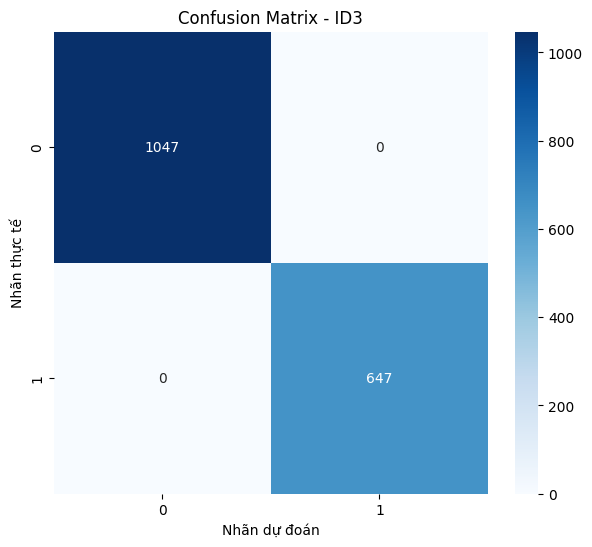

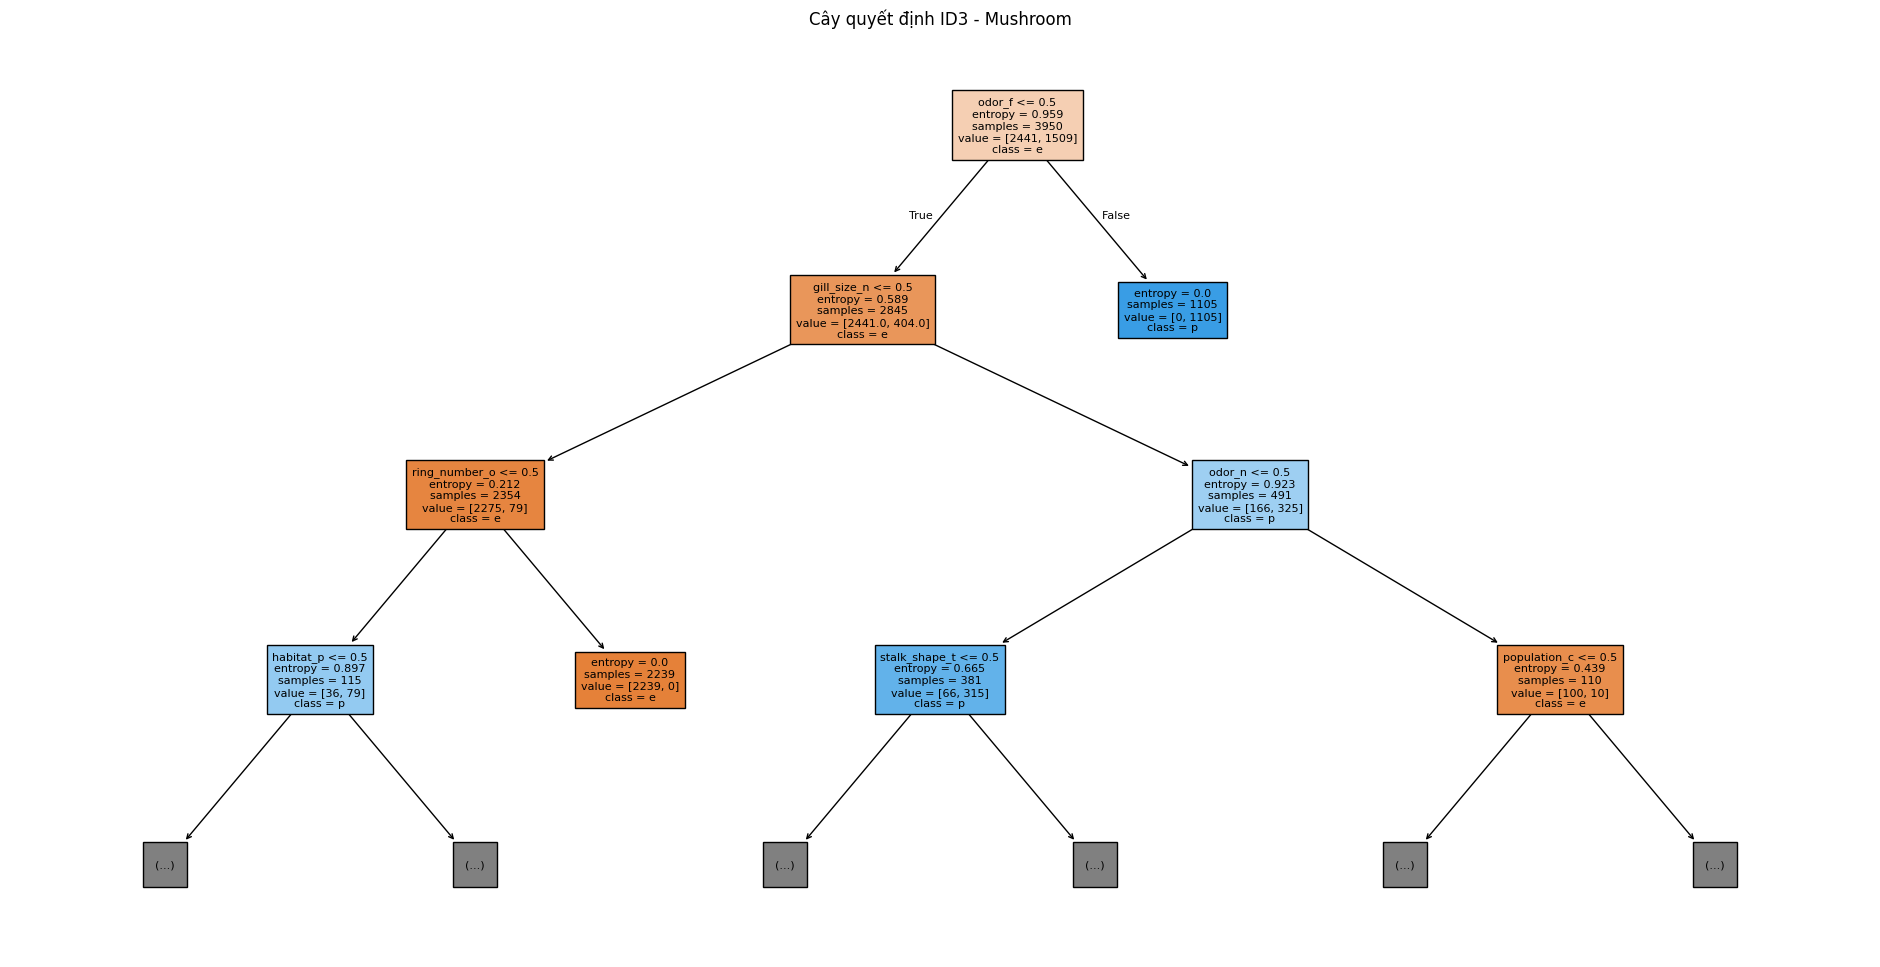

In [4]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

id3_model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

id3_model.fit(X_train, y_train)
y_pred_id3 = id3_model.predict(X_test)

cm_id3 = confusion_matrix(y_test, y_pred_id3)

print("Ma trận nhầm lẫn ID3:")
print(cm_id3)

print("\nBáo cáo phân loại:")
print(classification_report(y_test, y_pred_id3, zero_division=0))

print("Accuracy:", accuracy_score(y_test, y_pred_id3))
print("Precision:", precision_score(
    y_test, y_pred_id3, average="weighted", zero_division=0
))
print("Recall:", recall_score(
    y_test, y_pred_id3, average="weighted", zero_division=0
))

plt.figure(figsize=(7, 6))
sns.heatmap(cm_id3, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - ID3")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.show()

plt.figure(figsize=(24, 12))
plot_tree(
    id3_model,
    feature_names=X_train.columns,
    class_names=[str(x) for x in id3_model.classes_],
    filled=True,
    max_depth=3,
    fontsize=8
)
plt.title("Cây quyết định ID3 - Mushroom")
plt.savefig("mushroom_ID3.png", dpi=100, bbox_inches="tight")
plt.show()

Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008
Ma trận nhầm lẫn CART:
[[1047    0]
 [   0  647]]

Báo cáo phân loại:
              precision    recall  f1-score   support

           e       1.00      1.00      1.00      1047
           p       1.00      1.00      1.00       647

    accuracy                           1.00      1694
   macro avg       1.00      1.00      1.00      1694
weighted avg       1.00      1.00      1.00      1694

Accuracy: 1.0
Precision: 1.0
Recall: 1.0


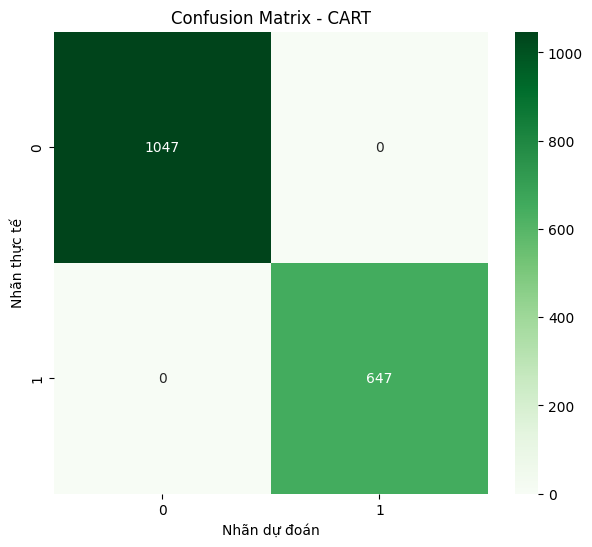

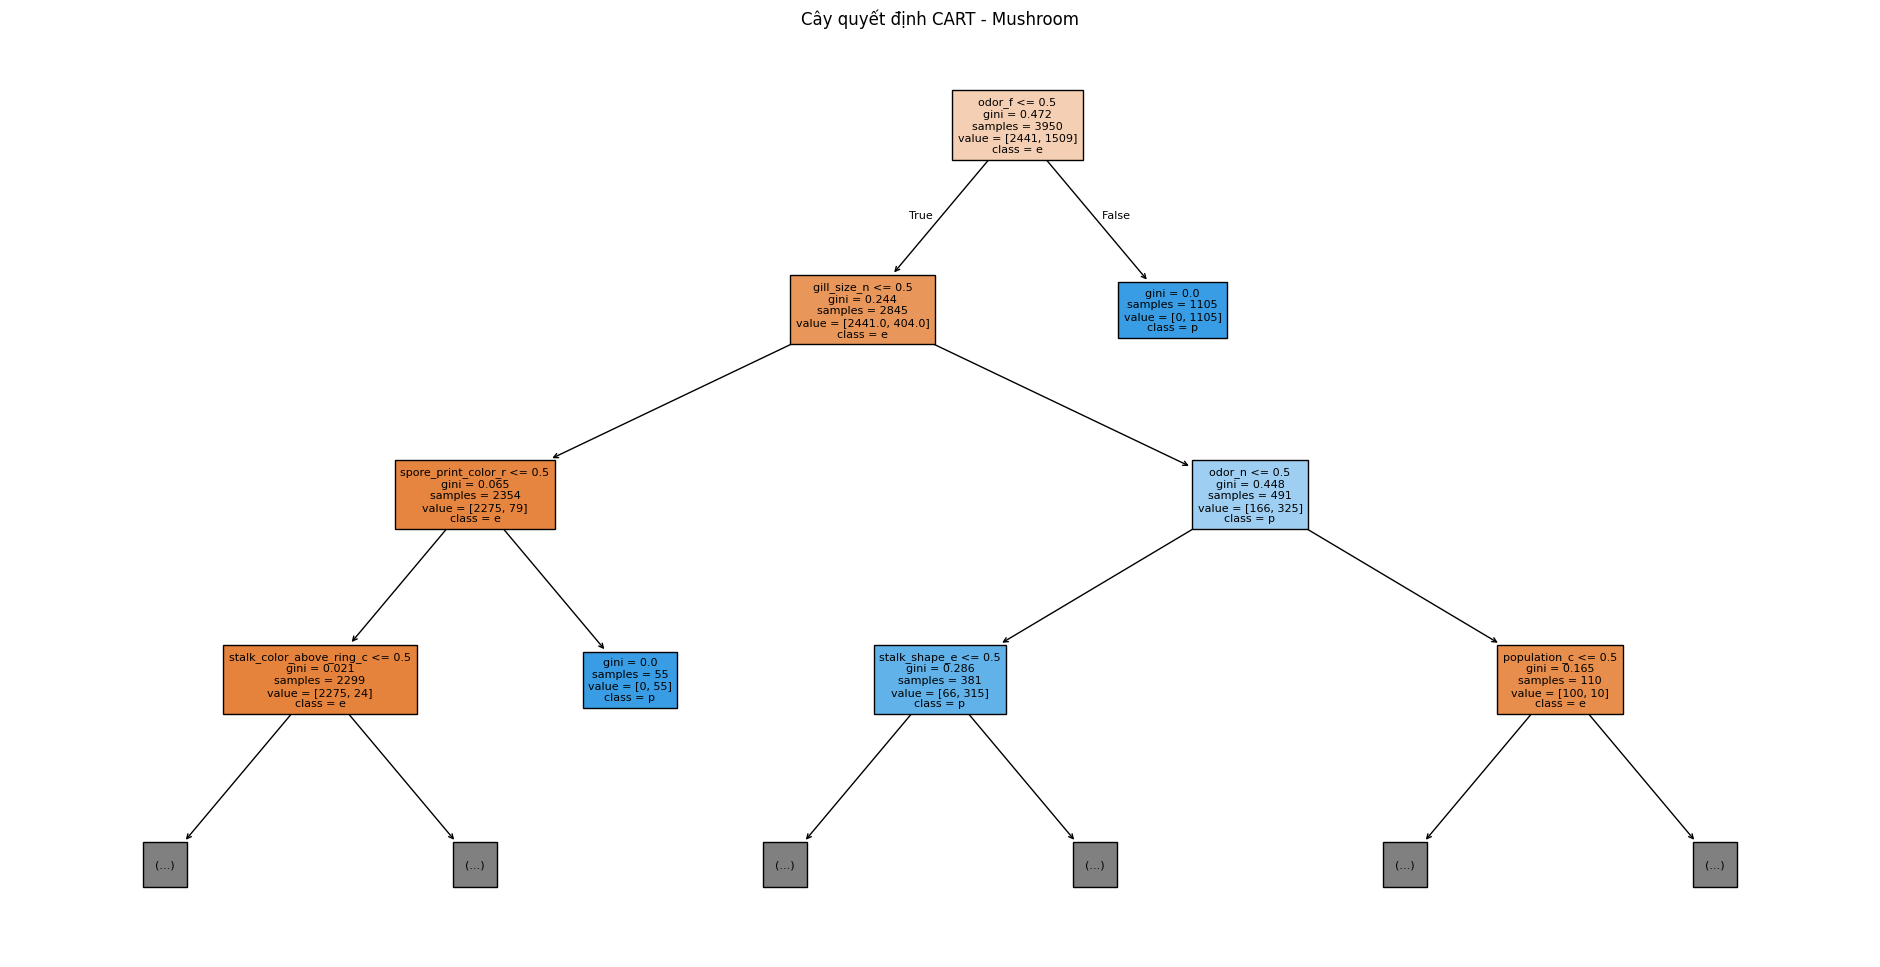

In [5]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

cart_model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

cart_model.fit(X_train, y_train)
y_pred_cart = cart_model.predict(X_test)

cm_cart = confusion_matrix(y_test, y_pred_cart)

print("Ma trận nhầm lẫn CART:")
print(cm_cart)

print("\nBáo cáo phân loại:")
print(classification_report(y_test, y_pred_cart, zero_division=0))

print("Accuracy:", accuracy_score(y_test, y_pred_cart))
print("Precision:", precision_score(
    y_test, y_pred_cart, average="weighted", zero_division=0
))
print("Recall:", recall_score(
    y_test, y_pred_cart, average="weighted", zero_division=0
))

plt.figure(figsize=(7, 6))
sns.heatmap(cm_cart, annot=True, fmt="d", cmap="Greens")
plt.title("Confusion Matrix - CART")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.show()

plt.figure(figsize=(24, 12))
plot_tree(
    cart_model,
    feature_names=X_train.columns,
    class_names=[str(x) for x in cart_model.classes_],
    filled=True,
    max_depth=3,
    fontsize=8
)
plt.title("Cây quyết định CART - Mushroom")
plt.savefig("mushroom_CART.png", dpi=100, bbox_inches="tight")
plt.show()

Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008
Ma trận nhầm lẫn Naïve Bayes:
[[1043    4]
 [   0  647]]

Báo cáo phân loại:
              precision    recall  f1-score   support

           e       1.00      1.00      1.00      1047
           p       0.99      1.00      1.00       647

    accuracy                           1.00      1694
   macro avg       1.00      1.00      1.00      1694
weighted avg       1.00      1.00      1.00      1694

Accuracy: 0.9976387249114522
Precision: 0.9976532335141467
Recall: 0.9976387249114522


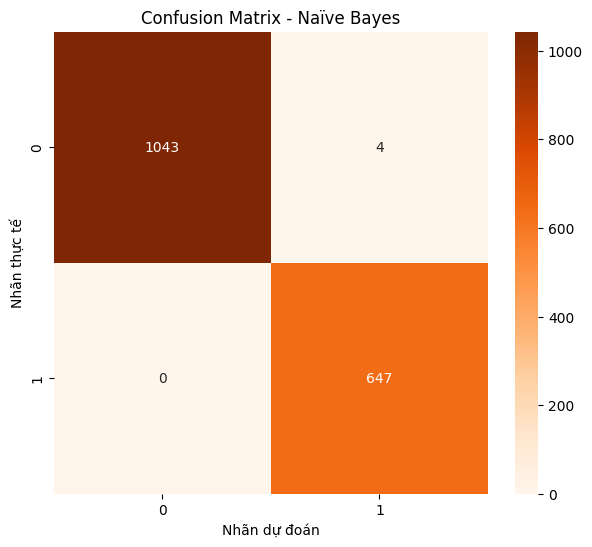

In [6]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

nb_model = GaussianNB()

nb_model.fit(X_train, y_train)
y_pred_nb = nb_model.predict(X_test)

cm_nb = confusion_matrix(y_test, y_pred_nb)

print("Ma trận nhầm lẫn Naïve Bayes:")
print(cm_nb)

print("\nBáo cáo phân loại:")
print(classification_report(y_test, y_pred_nb, zero_division=0))

print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print("Precision:", precision_score(
    y_test, y_pred_nb, average="weighted", zero_division=0
))
print("Recall:", recall_score(
    y_test, y_pred_nb, average="weighted", zero_division=0
))

plt.figure(figsize=(7, 6))
sns.heatmap(cm_nb, annot=True, fmt="d", cmap="Oranges")
plt.title("Confusion Matrix - Naïve Bayes")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.show()

Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008


,Mô hình,Accuracy,Precision,Recall,F1-score
0,ID3,1.000000,1.000000,1.000000,1.00000
1,CART,1.000000,1.000000,1.000000,1.00000
2,Naïve Bayes,0.997639,0.997653,0.997639,0.99764


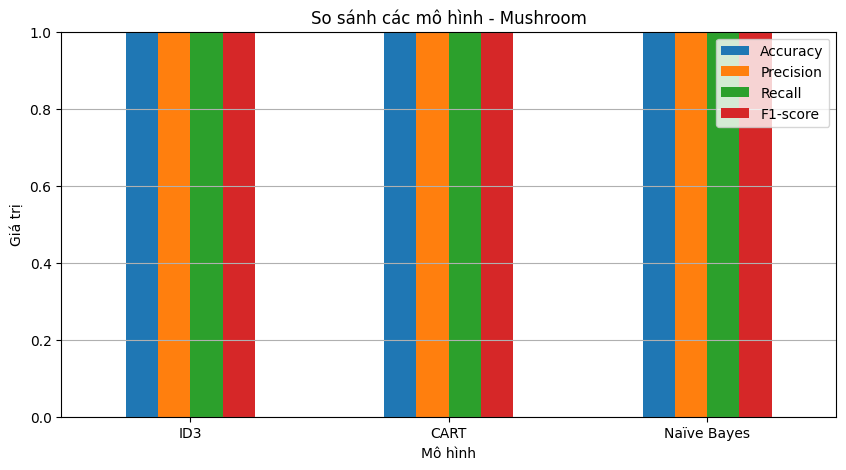

Mô hình có Accuracy cao nhất: ID3


In [7]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

results_mushroom = pd.DataFrame({
    "Mô hình": ["ID3", "CART", "Naïve Bayes"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_id3),
        accuracy_score(y_test, y_pred_cart),
        accuracy_score(y_test, y_pred_nb)
    ],
    "Precision": [
        precision_score(y_test, y_pred_id3, average="weighted", zero_division=0),
        precision_score(y_test, y_pred_cart, average="weighted", zero_division=0),
        precision_score(y_test, y_pred_nb, average="weighted", zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred_id3, average="weighted", zero_division=0),
        recall_score(y_test, y_pred_cart, average="weighted", zero_division=0),
        recall_score(y_test, y_pred_nb, average="weighted", zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_id3, average="weighted", zero_division=0),
        f1_score(y_test, y_pred_cart, average="weighted", zero_division=0),
        f1_score(y_test, y_pred_nb, average="weighted", zero_division=0)
    ]
})

display(results_mushroom)

results_mushroom.set_index("Mô hình")[
    ["Accuracy", "Precision", "Recall", "F1-score"]
].plot(kind="bar", figsize=(10, 5))

plt.title("So sánh các mô hình - Mushroom")
plt.ylabel("Giá trị")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

print(
    "Mô hình có Accuracy cao nhất:",
    results_mushroom.loc[
        results_mushroom["Accuracy"].idxmax(), "Mô hình"
    ]
)